<a href="https://colab.research.google.com/github/Dimas-091206/Proyek-Akhir-Kelompok-9-Online-Retail-II/blob/main/Varian_2_Klasifikasi_Online_retail_II_(k%3D3%2C_5%2C_7%2C_9%2C_11%2C_15).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Akhir Pembelajaran Mesin: Klasifikasi Negara Pelanggan (UK vs non-UK)
## Anggota 2 (Varian Parameter): k-NN dengan k = 3, 5, 7, 9, 11, 15

**Dataset:** Online Retail II (data pelanggan hasil agregasi, sudah bersih)
**Target:** `kelompok_negara` (UK / non-UK)
**Fitur (6):** recency, frekuensi, total_belanja, produk_unik, total_item, n_faktur_batal

**Tugas:** menjalankan k-NN dengan k = 3, 5, 7, 9, 11, 15, membuat grafik akurasi terhadap k,
dan mencari nilai k terbaik. Pembagian data, penskalaan, dan garis dasar 91,15% sama persis
dengan notebook Anggota 1 supaya hasilnya sebanding.

## Langkah 1. Impor pustaka dan tentukan daftar k

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score
)

RANDOM_STATE = 42
DAFTAR_K = [3, 5, 7, 9, 11, 15]

## Langkah 2. Mengambil dataset dari Google Drive

Dataset diunduh otomatis dari Drive, jadi tidak perlu upload manual tiap kali.
Pastikan akses file di Drive adalah **"Siapa saja yang memiliki link"** (Viewer).
`FILE_ID` di bawah sama dengan yang dipakai Anggota 1. Kalau file-nya kamu upload ulang ke
Drive sendiri, ganti dengan `XXXX` dari link `https://drive.google.com/file/d/XXXX/view`.

In [ ]:
import gdown

FILE_ID = "1ce3K3K2Vet0XDI7uSp6A44pUXnJC3BpW"   # ganti kalau pakai file Drive sendiri
OUTPUT  = "data_bersih_pelanggan.csv"

gdown.download(id=FILE_ID, output=OUTPUT, quiet=False)

df = pd.read_csv(OUTPUT)
print("Ukuran data:", df.shape)
df.head()

Downloading...
From: https://drive.google.com/uc?id=1ce3K3K2Vet0XDI7uSp6A44pUXnJC3BpW
To: /content/data_bersih_pelanggan.csv
100%|██████████| 481k/481k [00:00<00:00, 80.8MB/s]

Ukuran data: (5852, 14)


,Customer ID,total_belanja,frekuensi,recency,tenure_hari,produk_unik,total_item,n_faktur_batal,rata_nilai_faktur,nilai_batal,total_belanja_bersih,negara,n_negara,kelompok_negara
0,12346,77352.96,3,325,647,25,74239,1.0,25784.32000,-77183.60,169.36,United Kingdom,1,UK
1,12347,4921.53,8,2,404,126,2967,0.0,615.19125,0.00,4921.53,Iceland,1,non-UK
2,12348,1658.40,5,75,438,24,2704,0.0,331.68000,0.00,1658.40,Finland,1,non-UK
3,12349,3678.69,3,18,589,137,1621,1.0,1226.23000,-24.15,3654.54,Italy,1,non-UK
4,12350,294.40,1,310,310,16,196,0.0,294.40000,0.00,294.40,Norway,1,non-UK


## Langkah 3. Garis dasar (baseline)

Garis dasar = akurasi model "bodoh" yang selalu menebak kelas mayoritas (UK).
Grafik akurasi terhadap k nanti dibandingkan dengan angka ini.

In [ ]:
dist = df["kelompok_negara"].value_counts()
dist_pct = df["kelompok_negara"].value_counts(normalize=True) * 100
print(pd.DataFrame({"jumlah": dist, "persen": dist_pct.round(2)}))

BASELINE = dist_pct["UK"]
print(f"\nGaris dasar (tebak selalu UK) = {BASELINE:.2f}%")

                 jumlah  persen
kelompok_negara                
UK                 5334   91.15
non-UK              518    8.85

Garis dasar (tebak selalu UK) = 91.15%


## Langkah 4. Memilih fitur dan target

Enam fitur sesuai proposal (Bagian C). `negara` dan `n_negara` tidak dipakai karena
menyusun target (kebocoran data). Target: **UK = 0, non-UK = 1** (non-UK = kelas positif).

In [ ]:
FITUR = ["recency", "frekuensi", "total_belanja",
         "produk_unik", "total_item", "n_faktur_batal"]

X = df[FITUR]
y = (df["kelompok_negara"] == "non-UK").astype(int)

print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)

Bentuk X: (5852, 6) | Bentuk y: (5852,)


## Langkah 5. Pembagian data latih/uji (berstrata) dan penskalaan

Pembagian 80:20 dengan `stratify=y` dan `random_state=42`, sama dengan Anggota 1.
Scaler **hanya di-fit pada data latih**, lalu dipakai untuk mentransformasi data uji
(mencegah kebocoran data). Penskalaan wajib untuk k-NN karena berbasis jarak.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

baseline_uji = (y_test == 0).mean() * 100
print(f"Garis dasar di data uji: {baseline_uji:.2f}%")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit hanya di data latih
X_test_s  = scaler.transform(X_test)        # data uji hanya ditransformasi

Data latih: (4681, 6) | Data uji: (1171, 6)
Garis dasar di data uji: 91.12%


## Langkah 6. Melatih k-NN untuk setiap nilai k

Satu model dilatih untuk tiap k (3, 5, 7, 9, 11, 15), lalu dievaluasi di data uji.
Selain akurasi, dicatat precision, recall, F1 (kelas non-UK), balanced accuracy,
dan isi confusion matrix (TP/FP/FN/TN), karena akurasi saja bisa menyesatkan
pada kelas yang sangat timpang.

In [ ]:
baris, cm_per_k = [], {}

for k in DAFTAR_K:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    cm_per_k[k] = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm_per_k[k].ravel()

    baris.append({
        "k": k,
        "akurasi": accuracy_score(y_test, y_pred),
        "precision_nonUK": precision_score(y_test, y_pred, zero_division=0),
        "recall_nonUK": recall_score(y_test, y_pred, zero_division=0),
        "f1_nonUK": f1_score(y_test, y_pred, zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_test, y_pred),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    })

hasil = pd.DataFrame(baris).set_index("k")
display(hasil.round(4))

,akurasi,precision_nonUK,recall_nonUK,f1_nonUK,balanced_acc,TP,FP,FN,TN
k,,,,,,,,,
3,0.8950,0.087,0.0192,0.0315,0.4998,2,21,102,1046
5,0.9061,0.000,0.0000,0.0000,0.4972,0,6,104,1061
7,0.9095,0.000,0.0000,0.0000,0.4991,0,2,104,1065
9,0.9112,0.000,0.0000,0.0000,0.5000,0,0,104,1067
11,0.9112,0.000,0.0000,0.0000,0.5000,0,0,104,1067
15,0.9112,0.000,0.0000,0.0000,0.5000,0,0,104,1067


## Langkah 7. Confusion matrix untuk semua k

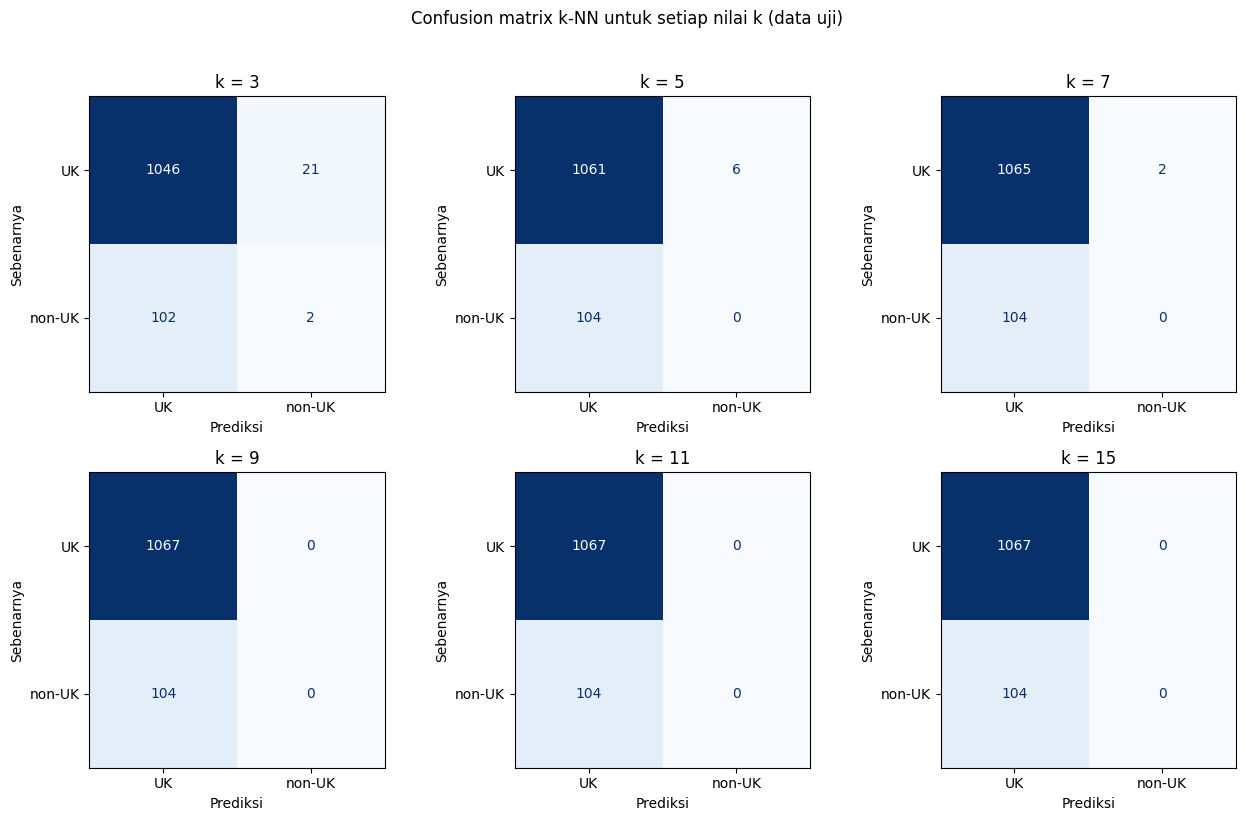

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, k in zip(axes.ravel(), DAFTAR_K):
    ConfusionMatrixDisplay(cm_per_k[k], display_labels=["UK", "non-UK"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"k = {k}")
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
plt.suptitle("Confusion matrix k-NN untuk setiap nilai k (data uji)", y=1.02)
plt.tight_layout()
plt.show()

## Langkah 8. Grafik akurasi terhadap k (data uji)

Garis merah putus-putus adalah garis dasar 91,15%.

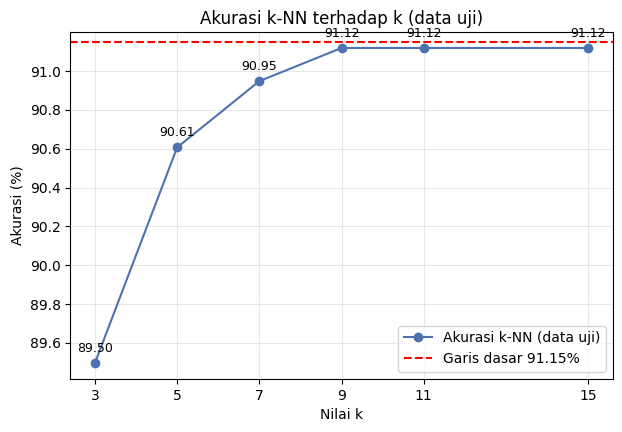

In [ ]:
akurasi_pct = hasil["akurasi"] * 100

plt.figure(figsize=(7, 4.5))
plt.plot(DAFTAR_K, akurasi_pct, marker="o", color="#4C72B0", label="Akurasi k-NN (data uji)")
plt.axhline(BASELINE, color="red", linestyle="--", label=f"Garis dasar {BASELINE:.2f}%")
for k, v in zip(DAFTAR_K, akurasi_pct):
    plt.annotate(f"{v:.2f}", (k, v), textcoords="offset points",
                 xytext=(0, 8), ha="center", fontsize=9)
plt.xticks(DAFTAR_K)
plt.xlabel("Nilai k")
plt.ylabel("Akurasi (%)")
plt.title("Akurasi k-NN terhadap k (data uji)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Langkah 9. Validasi silang 5-fold (pemilihan k yang lebih stabil)

Satu kali split bisa kebetulan menguntungkan atau merugikan satu nilai k. Validasi silang berstrata
memberi gambaran yang lebih stabil. Scaler dimasukkan ke dalam *pipeline* agar di-fit ulang di tiap
lipatan (tanpa kebocoran data).

,akurasi_cv_mean,akurasi_cv_std,recall_cv_mean,f1_cv_mean
k,,,,
3,0.8964,0.0026,0.0483,0.0759
5,0.9079,0.0028,0.0213,0.0389
7,0.9099,0.0018,0.0077,0.0149
9,0.9110,0.0006,0.0039,0.0076
11,0.9115,0.0004,0.0019,0.0038
15,0.9115,0.0004,0.0000,0.0000


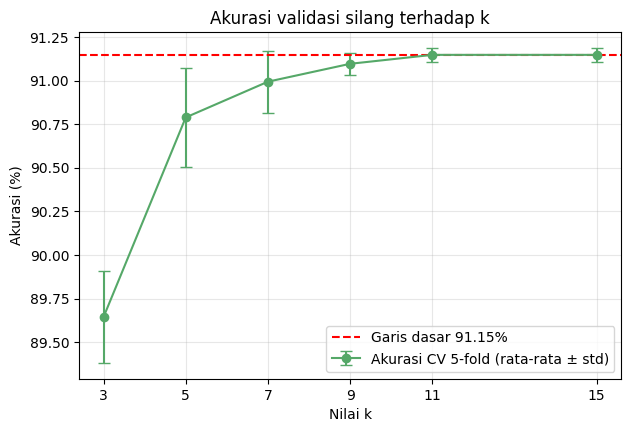

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baris_cv = []
for k in DAFTAR_K:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=k))])
    skor = cross_validate(pipe, X, y, cv=skf, scoring=["accuracy", "recall", "f1"])
    baris_cv.append({
        "k": k,
        "akurasi_cv_mean": skor["test_accuracy"].mean(),
        "akurasi_cv_std": skor["test_accuracy"].std(),
        "recall_cv_mean": skor["test_recall"].mean(),
        "f1_cv_mean": skor["test_f1"].mean(),
    })

hasil_cv = pd.DataFrame(baris_cv).set_index("k")
display(hasil_cv.round(4))

plt.figure(figsize=(7, 4.5))
plt.errorbar(DAFTAR_K, hasil_cv["akurasi_cv_mean"] * 100,
             yerr=hasil_cv["akurasi_cv_std"] * 100,
             marker="o", capsize=4, color="#55A868",
             label="Akurasi CV 5-fold (rata-rata ± std)")
plt.axhline(BASELINE, color="red", linestyle="--", label=f"Garis dasar {BASELINE:.2f}%")
plt.xticks(DAFTAR_K)
plt.xlabel("Nilai k"); plt.ylabel("Akurasi (%)")
plt.title("Akurasi validasi silang terhadap k")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Langkah 10. Metrik kelas non-UK terhadap k

Sesuai proposal, evaluasi tidak berhenti di akurasi. Grafik ini menunjukkan seberapa baik
tiap k benar-benar mengenali pelanggan non-UK.

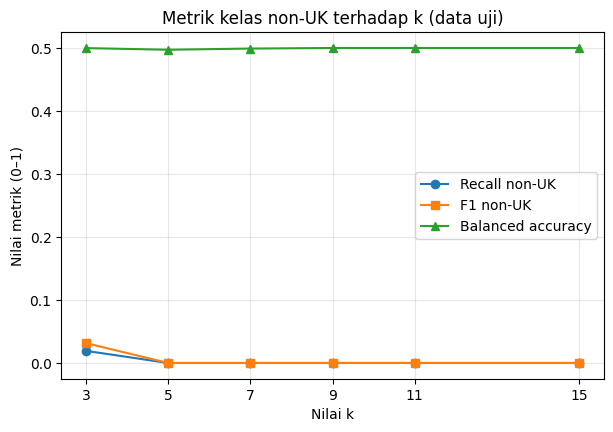

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(DAFTAR_K, hasil["recall_nonUK"], marker="o", label="Recall non-UK")
ax.plot(DAFTAR_K, hasil["f1_nonUK"], marker="s", label="F1 non-UK")
ax.plot(DAFTAR_K, hasil["balanced_acc"], marker="^", label="Balanced accuracy")
ax.set_xticks(DAFTAR_K)
ax.set_xlabel("Nilai k"); ax.set_ylabel("Nilai metrik (0–1)")
ax.set_title("Metrik kelas non-UK terhadap k (data uji)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## Langkah 11. Menentukan k terbaik

Kriteria utama sesuai tugas: **akurasi tertinggi**. Jika beberapa k seri, dipilih k terkecil
(model paling sederhana). Sebagai pembanding, ditampilkan juga k terbaik menurut validasi silang
dan k dengan recall non-UK tertinggi.

In [ ]:
akurasi_maks = hasil["akurasi"].max()
kandidat_seri = list(hasil.index[hasil["akurasi"] == akurasi_maks])
k_terbaik_uji = int(min(kandidat_seri))

cv_maks = hasil_cv["akurasi_cv_mean"].max()
k_terbaik_cv = int(hasil_cv.index[np.isclose(hasil_cv["akurasi_cv_mean"], cv_maks)].min())

k_recall = int(hasil["recall_nonUK"].idxmax())

print(f"K terbaik menurut akurasi data uji : k = {k_terbaik_uji} "
      f"({akurasi_maks*100:.2f}%) | k yang seri: {kandidat_seri}")
print(f"K terbaik menurut akurasi CV 5-fold: k = {k_terbaik_cv} ({cv_maks*100:.2f}%)")
print(f"K dengan recall non-UK tertinggi   : k = {k_recall} "
      f"(recall = {hasil.loc[k_recall, 'recall_nonUK']:.4f})")

K_TERBAIK = k_terbaik_uji
rk = hasil.loc[K_TERBAIK]
print(f"\nModel k = {K_TERBAIK}: TP = {int(rk['TP'])}, FN = {int(rk['FN'])}, "
      f"FP = {int(rk['FP'])}, TN = {int(rk['TN'])}")
print(f"Selisih akurasi terhadap garis dasar {BASELINE:.2f}%       : "
      f"{rk['akurasi']*100 - BASELINE:+.2f} poin persen")
print(f"Selisih akurasi terhadap garis dasar data uji {baseline_uji:.2f}%: "
      f"{rk['akurasi']*100 - baseline_uji:+.2f} poin persen")

K terbaik menurut akurasi data uji : k = 9 (91.12%) | k yang seri: [9, 11, 15]
K terbaik menurut akurasi CV 5-fold: k = 11 (91.15%)
K dengan recall non-UK tertinggi   : k = 3 (recall = 0.0192)

Model k = 9: TP = 0, FN = 104, FP = 0, TN = 1067
Selisih akurasi terhadap garis dasar 91.15%       : -0.03 poin persen
Selisih akurasi terhadap garis dasar data uji 91.12%: +0.00 poin persen


## Langkah 12. Kesimpulan

- Akurasi naik seiring k membesar: 89,50% (k=3), 90,61% (k=5), 90,95% (k=7), lalu 91,12% (k=9, 11, 15).
- **k terbaik menurut akurasi = 9** (seri dengan k=11 dan k=15, dipilih yang terkecil). Menurut CV 5-fold,
  k = 11 dan 15 sedikit lebih tinggi (91,15%), selisihnya sangat kecil.
- Namun akurasi tertinggi itu **sama dengan garis dasar** (91,12% pada data uji, 91,15% pada data penuh).
  Tidak ada k yang mengalahkan garis dasar.
- Alasannya terlihat di confusion matrix: untuk k = 9, 11, 15 model menebak "UK" untuk semua
  pelanggan (TP = 0, FP = 0). Akurasi naik karena model makin sering menebak UK, bukan karena makin
  pandai mengenali non-UK.
- Satu-satunya k yang menemukan non-UK sama sekali adalah k = 3 (TP = 2 dari 104; recall 1,9%),
  dengan harga 21 pelanggan UK salah ditandai non-UK. Itu pun masih sangat lemah.
- Artinya enam fitur ini hampir tidak memisahkan UK dari non-UK, sejalan dengan temuan awal di proposal.
  Hasil ini jadi bahan pembanding untuk Anggota 3 (Naive Bayes).